# LoRA placement, rank and QLoRA on a frozen ViT under domain shift: results and demo

This notebook shows the project's results **without re-running the training** (252 training runs, about 11 GPU-hours).

1. **Results**: tables, significance tests and figures, loaded from the saved per-run results in `results/`.
2. **Live demo**: a trained LoRA adapter (`model/pacs_mlp4_sketch_s0`, 1.5 MB) classifies images. It was trained on
   PACS *photo, art painting and cartoon* only, so the **sketch** images are a domain it has never seen.

Runs on CPU. The demo downloads the frozen ViT-B/16 backbone (~350 MB) from the Hugging Face Hub on first use.

In [1]:
import json, glob, os
import pandas as pd
from IPython.display import Image, Markdown, display

pd.set_option("display.precision", 1)
COLS = {"label": "Method", "avg_acc": "Avg acc (%)", "std_seeds": "sd (seeds)", "worst_acc": "Worst domain (%)",
        "worst_domain": "Worst domain", "avg_f1": "Macro-F1", "adapter_params": "Trainable params",
        "peak_mem_mb": "Peak mem (MB)", "train_time_s": "Train time (s)", "n_runs": "Runs"}

def table(name):
    s = pd.read_csv(f"results/{name}_summary.csv")
    return s[list(COLS)].rename(columns=COLS).set_index("Method")

n_runs = sum(1 for f in ["results/results.jsonl", "results/local.jsonl"] for l in open(f) if l.strip())
print(f"{n_runs} logged runs (including LR tuning and smoke tests)")

268 logged runs (including LR tuning and smoke tests)


## 1. Results
### PACS (3 seeds x 4 held-out domains, Tesla T4)
Accuracy on the held-out domain, averaged over the 4 domains. All configurations in the same block of the study have
the same number of trainable parameters (147k for placement and layer-wise rank, 369k for attention vs MLP).

In [2]:
table("pacs_vit_b_e4")

,Avg acc (%),sd (seeds),Worst domain (%),Worst domain,Macro-F1,Trainable params,Peak mem (MB),Train time (s),Runs
Method,,,,,,,,,
Linear probe,69.5,0.8,33.4,sketch,72.3,0,858.6,91.2,12
BitFit,87.7,0.3,72.0,sketch,88.3,102912,3144.5,182.5,12
All blocks r1,86.5,1.4,69.0,sketch,87.1,36864,3746.4,206.8,12
All blocks r4,87.2,0.7,69.8,sketch,87.8,147456,3735.8,202.1,12
All blocks r16,85.3,1.4,64.3,sketch,86.0,589824,3743.1,204.0,12
Early (0-3) r12,85.1,0.1,68.4,sketch,85.6,147456,3285.4,184.8,12
Middle (4-7) r12,85.0,1.0,66.6,sketch,85.7,147456,2394.7,152.6,12
Late (8-11) r12,80.5,1.2,51.6,sketch,81.8,147456,1503.7,120.7,12
Increasing 1/4/7,86.5,1.0,67.0,sketch,87.3,147456,3728.6,206.1,12


### Office-Home (3 seeds x 4 held-out domains, AMD RX 9070 GRE)

In [3]:
table("officehome_vit_b_e4")

,Avg acc (%),sd (seeds),Worst domain (%),Worst domain,Macro-F1,Trainable params,Peak mem (MB),Train time (s),Runs
Method,,,,,,,,,
Linear probe,79.0,9.1e-02,59.0,Clipart,78.0,0,1050.5,91.3,12
BitFit,80.5,2.2e-01,64.2,Clipart,79.4,102912,3335.2,150.4,12
All blocks r4,81.4,1.6e-01,63.2,Clipart,80.4,147456,3905.4,169.5,12
Early (0-3) r12,81.1,3.2e-01,63.5,Clipart,80.0,147456,3448.5,151.7,12
Late (8-11) r12,80.6,1.9e-01,61.0,Clipart,79.6,147456,1667.4,115.4,12
"Attention q,v",80.7,1.7e-01,62.9,Clipart,79.8,368640,3867.3,169.5,12
"MLP fc1,fc2",81.8,1.3e-01,65.0,Clipart,80.7,368640,5048.8,215.7,12
QLoRA r4,80.9,1.4e-01,62.2,Clipart,80.0,147456,4803.1,222.7,12


### Paired significance tests
Mean accuracy difference A - B (points) over the 12 matched (held-out domain, seed) runs, with a paired t-test.
`A_wins` = in how many of the 12 pairs A was better.

In [4]:
p = pd.read_csv("results/pacs_vit_b_e4_paired_tests.csv")
o = pd.read_csv("results/officehome_vit_b_e4_paired_tests.csv")
p.merge(o, on=["A", "B"], how="left", suffixes=(" PACS", " Office-Home")).drop(columns=["n_pairs PACS", "n_pairs Office-Home"])

,A,B,mean_diff_pts PACS,A_wins PACS,p_value PACS,mean_diff_pts Office-Home,A_wins Office-Home,p_value Office-Home
0,early,r4,-2.1e+00,3,3.1e-03,-0.2,3.0,2.2e-01
1,middle,r4,-2.2e+00,4,1.5e-02,NaN,NaN,NaN
2,late,r4,-6.7e+00,0,1.0e-02,-0.8,2.0,2.5e-02
3,early,late,4.6e+00,8,6.9e-02,0.6,7.0,2.0e-01
4,middle,late,4.4e+00,9,5.5e-02,NaN,NaN,NaN
5,early,middle,1.5e-01,4,8.1e-01,NaN,NaN,NaN
6,r1,r4,-6.6e-01,4,3.0e-01,NaN,NaN,NaN
7,r16,r4,-1.9e+00,3,1.5e-01,NaN,NaN,NaN
8,inc,r4,-7.1e-01,4,3.0e-01,NaN,NaN,NaN
9,dec,r4,-7.9e-01,6,1.7e-01,NaN,NaN,NaN


### Key findings
| Question | Answer |
|---|---|
| RQ1 Where to put adapters? | Spread over **all** blocks. At the same budget, late-only adapters lose 6.7 points on PACS (worst on Sketch). |
| RQ2 How small can the rank be? | Rank 1 is within 0.7 points of rank 4; rank 16 is lower. Layer-wise rank profiles do not beat uniform rank. |
| RQ3 Attention or MLP? | MLP adapters beat attention adapters at the same budget on both datasets (+1.0 / +1.1). |
| RQ4 4-bit backbone (QLoRA)? | At most 0.5 points lost, but peak training memory goes **up** ~25% at ViT-B scale. |
| RQ5 Does it transfer? | Yes, the same trends hold on Office-Home with smaller gaps. |

### Figures

**fig2_project_architecture**

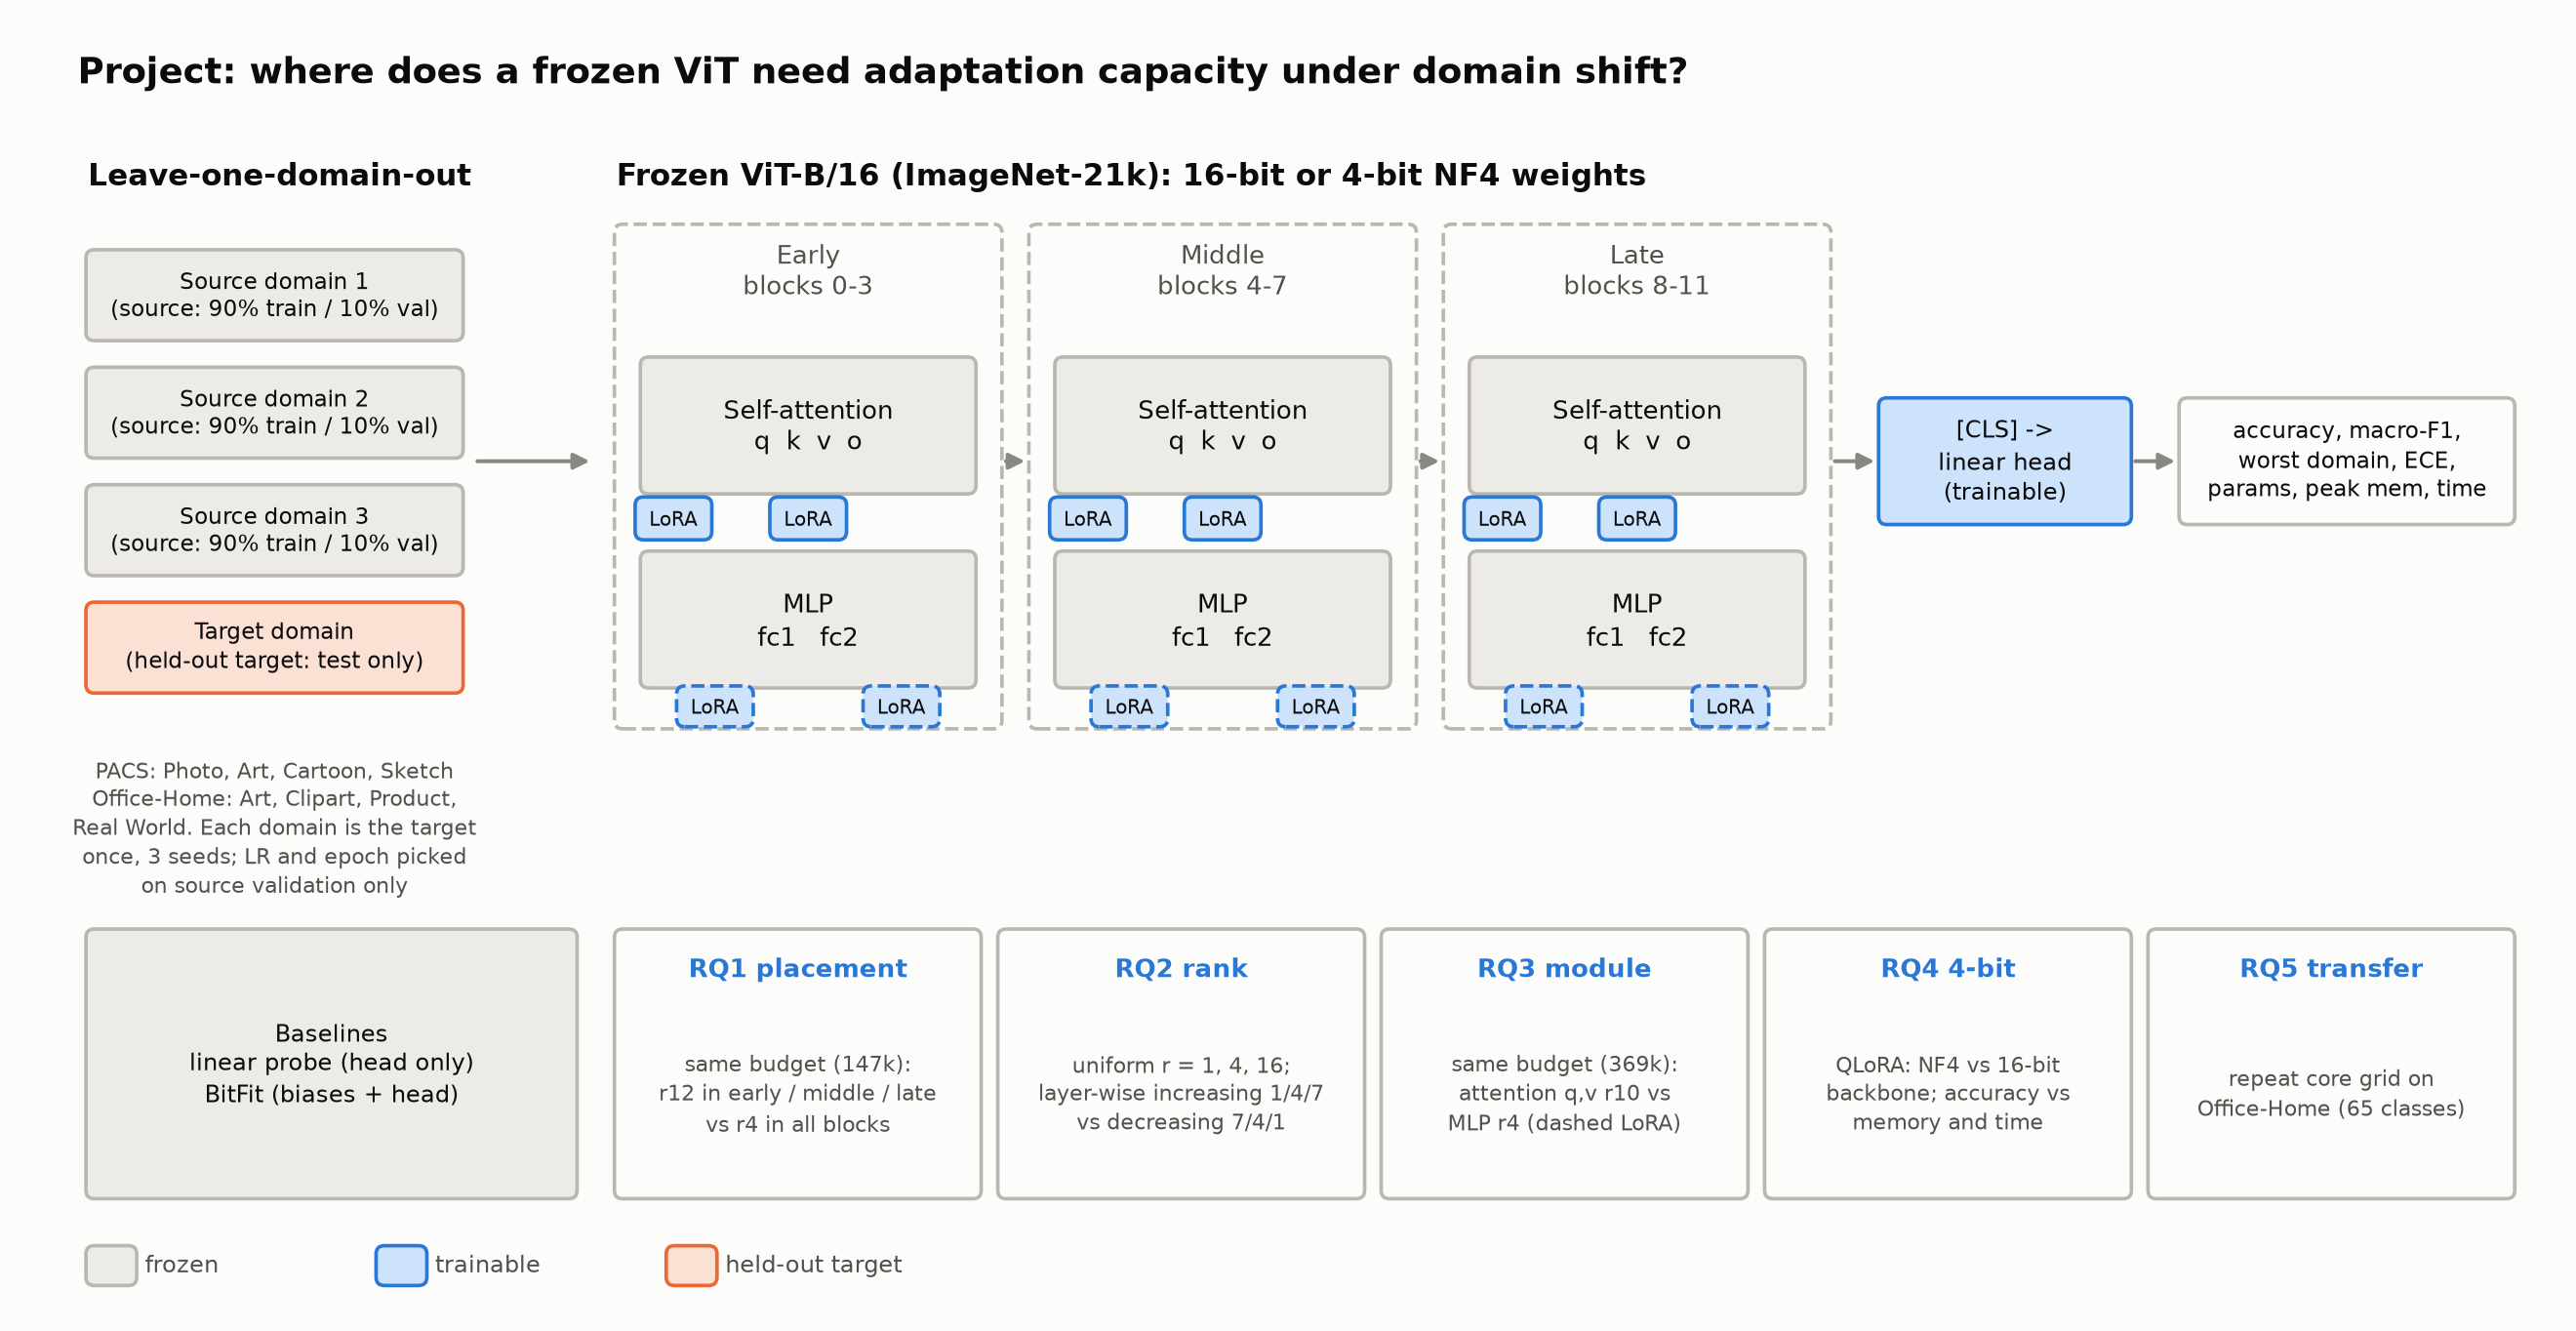

**pacs_vit_b_e4_placement_rank_module**

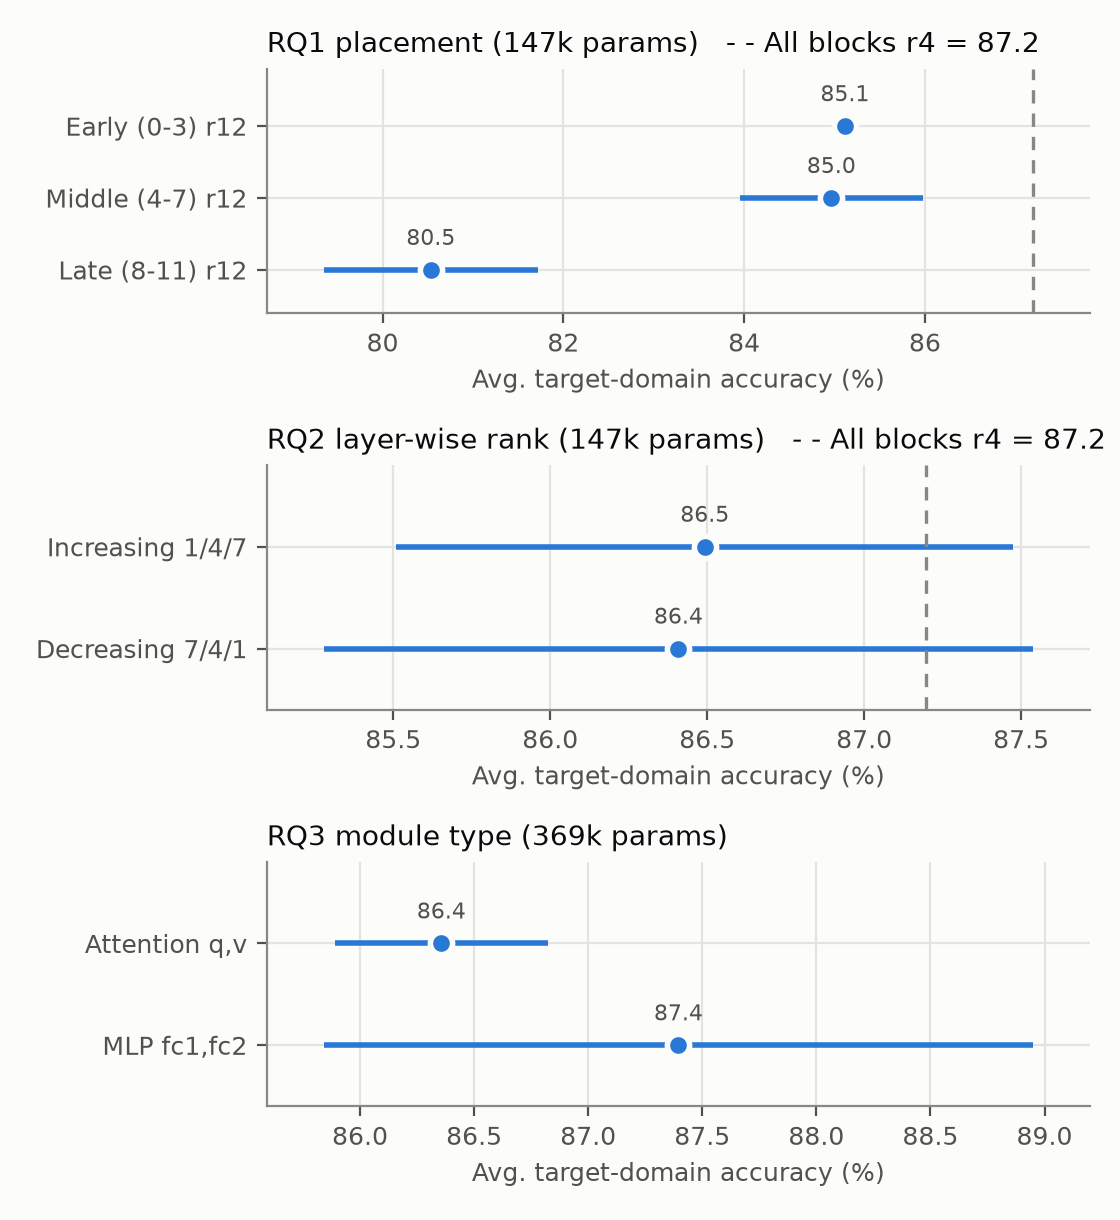

**pacs_vit_b_e4_rank**

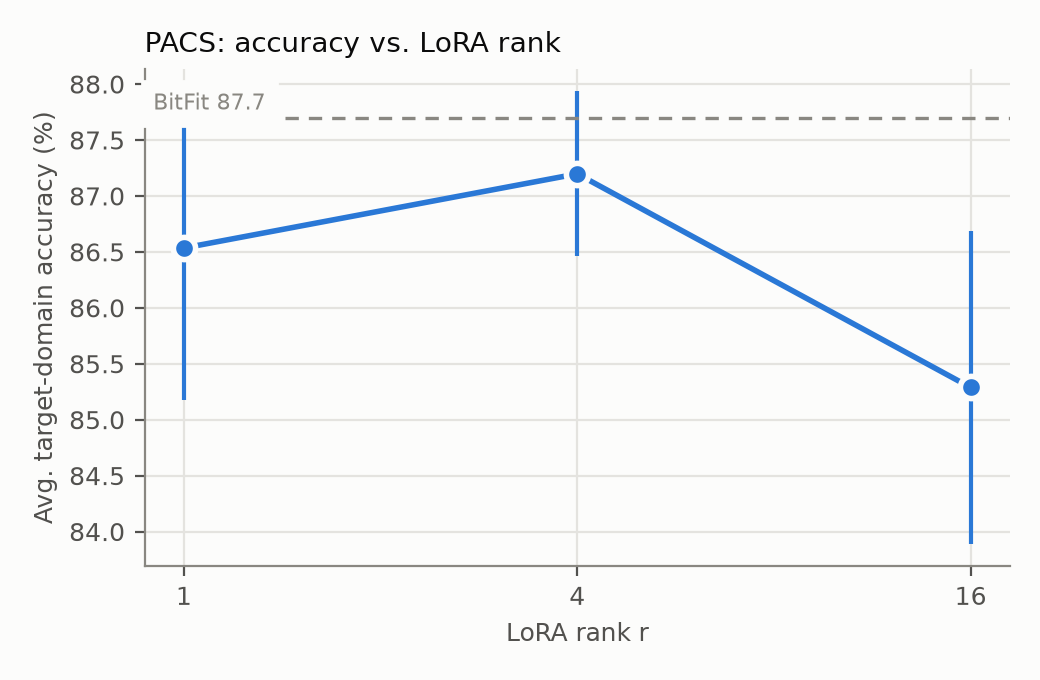

**pacs_vit_b_e4_qlora**

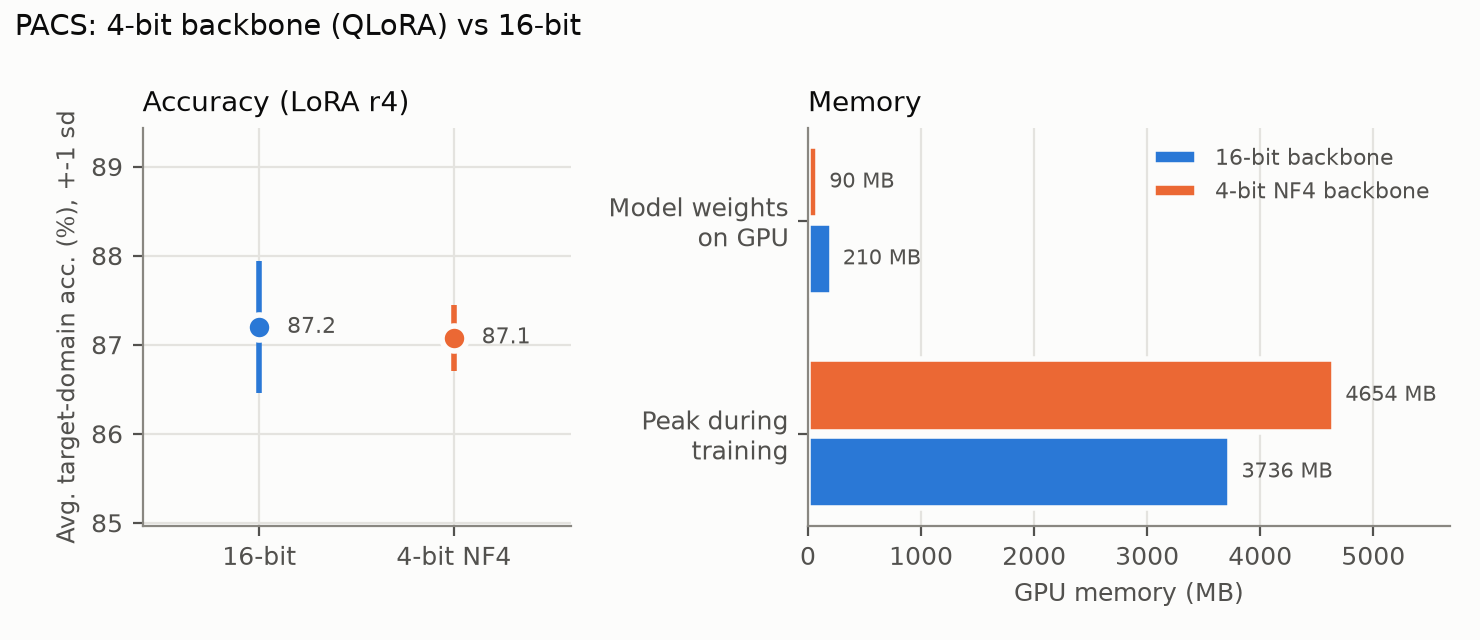

**officehome_vit_b_e4_qlora**

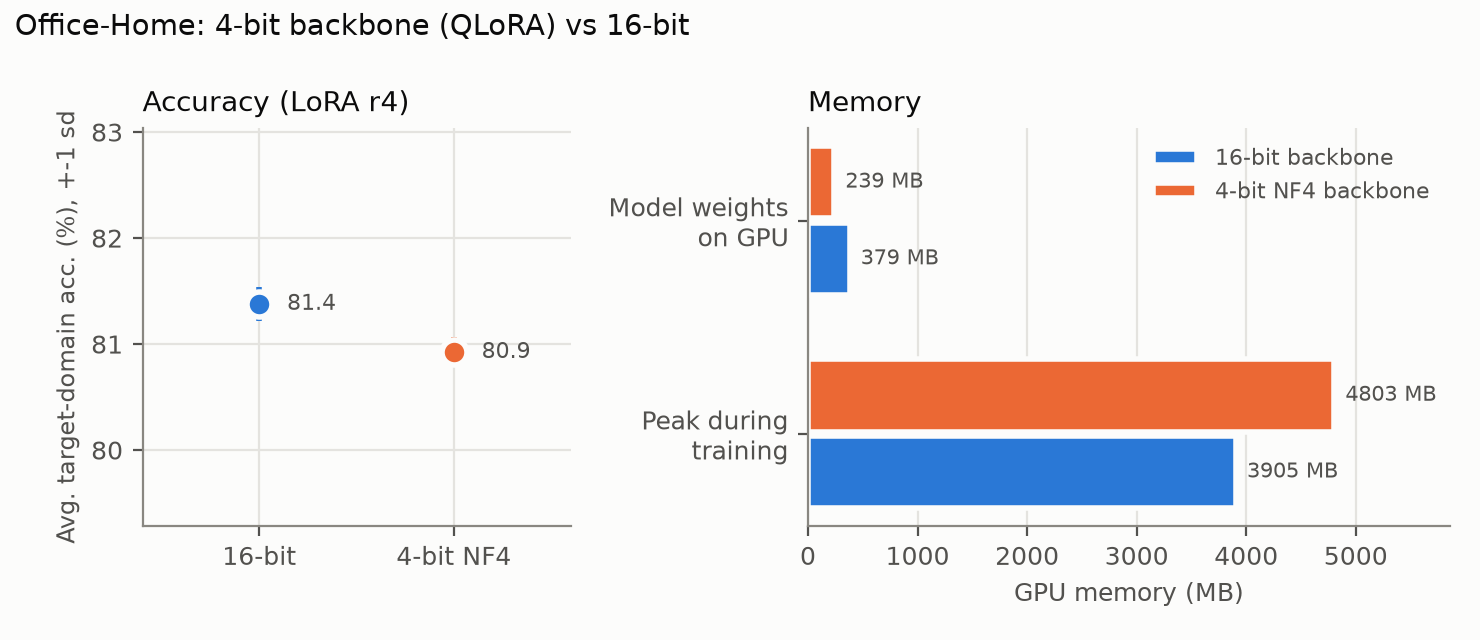

**pacs_vit_b_e4_per_domain**

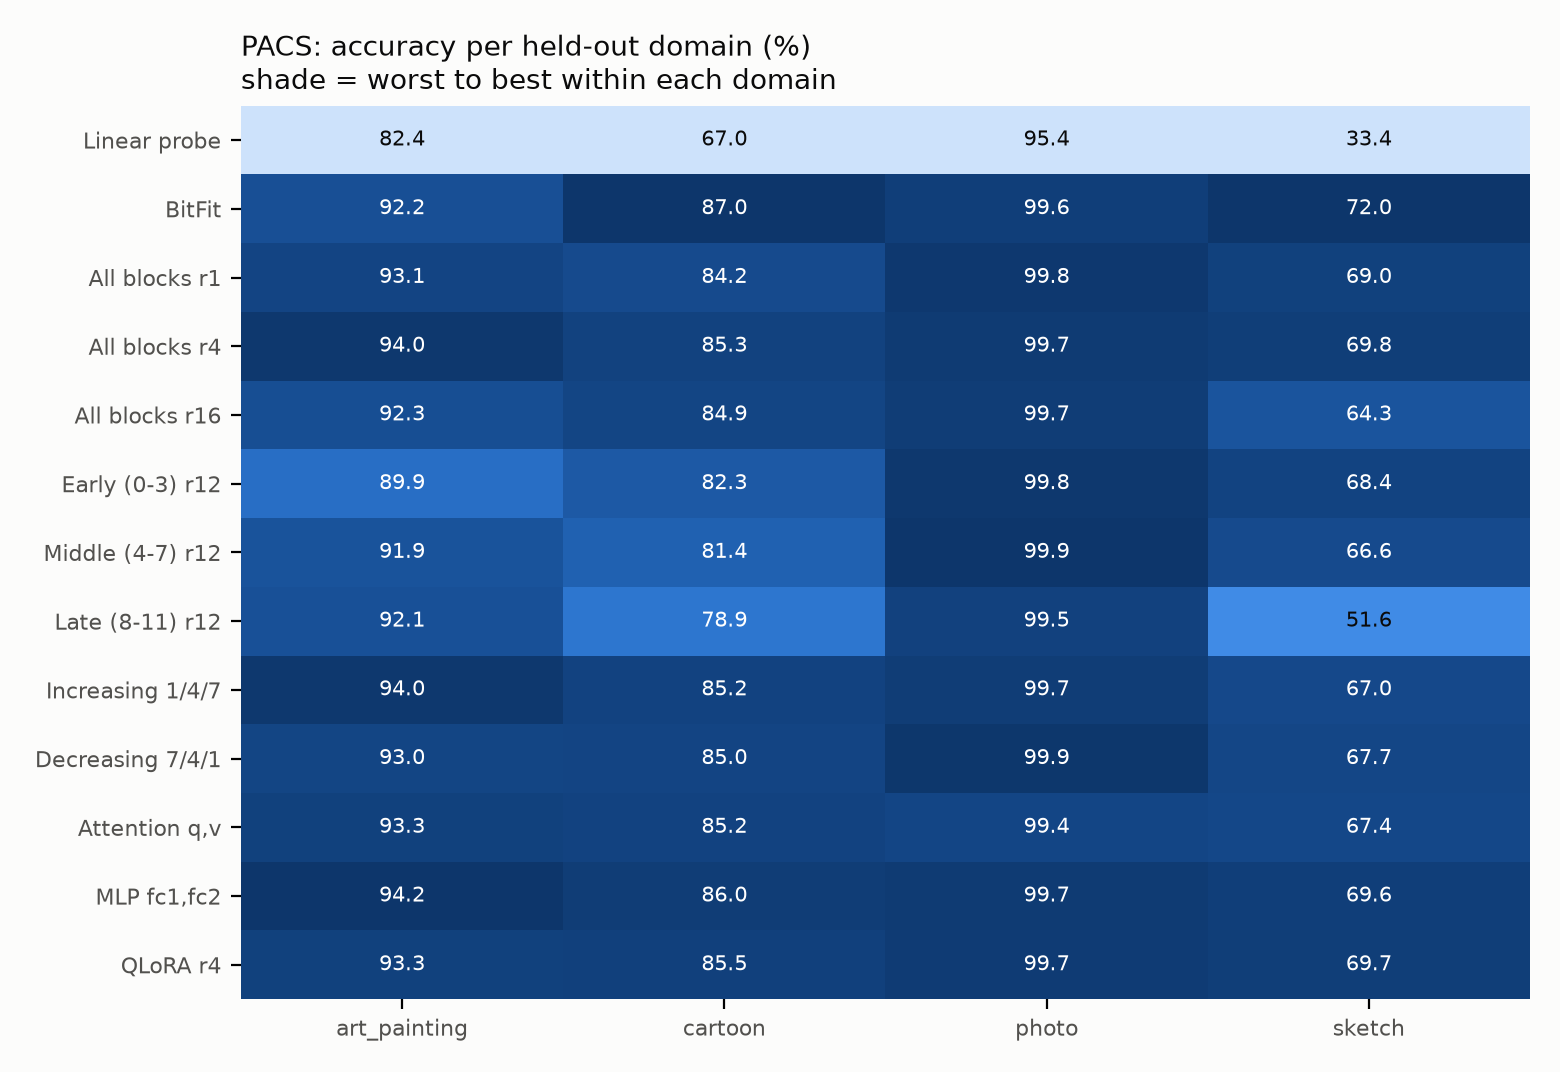

**officehome_vit_b_e4_placement_rank_module**

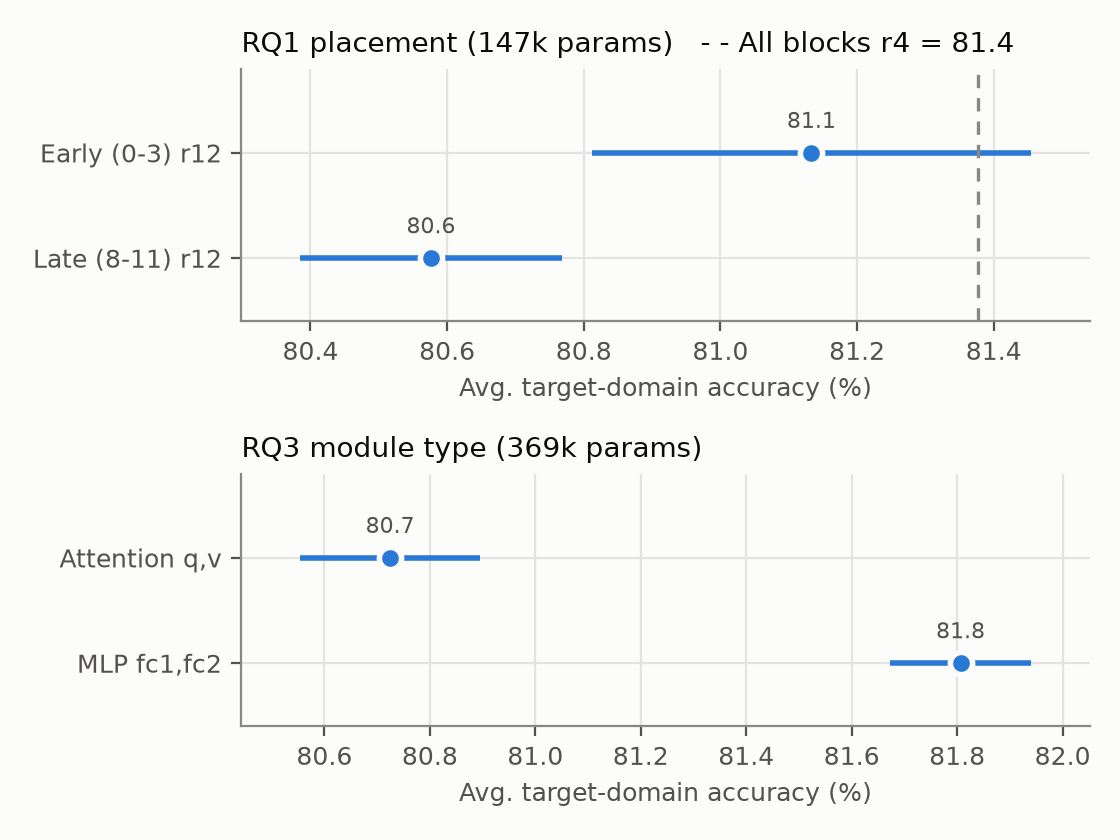

**officehome_vit_b_e4_per_domain**

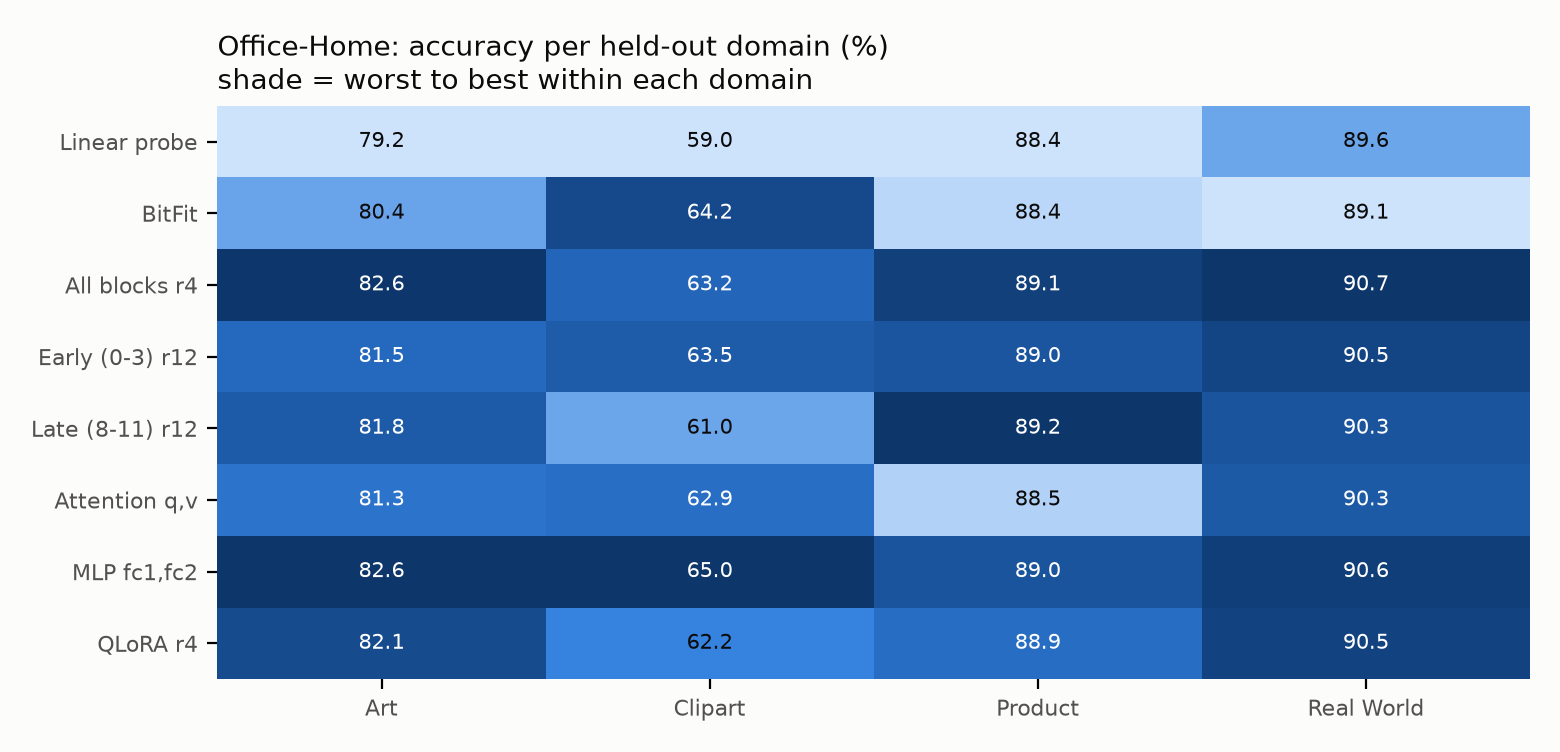

In [5]:
for f in ["fig2_project_architecture", "pacs_vit_b_e4_placement_rank_module", "pacs_vit_b_e4_rank",
          "pacs_vit_b_e4_qlora", "officehome_vit_b_e4_qlora", "pacs_vit_b_e4_per_domain",
          "officehome_vit_b_e4_placement_rank_module", "officehome_vit_b_e4_per_domain"]:
    display(Markdown(f"**{f}**"), Image(f"figures/{f}.png", width=760))

## 2. Live demo: classify images the model has never seen
The adapter is LoRA r=4 on the MLP layers of all 12 blocks (369k trainable parameters + head) on a frozen ViT-B/16,
trained on PACS photo + art painting + cartoon. Sketch was held out: its accuracy on all 3,929 sketch images was
measured after training (see `model/pacs_mlp4_sketch_s0/demo_info.json`).

Held-out domain: sketch, accuracy on all of it: 76.6%


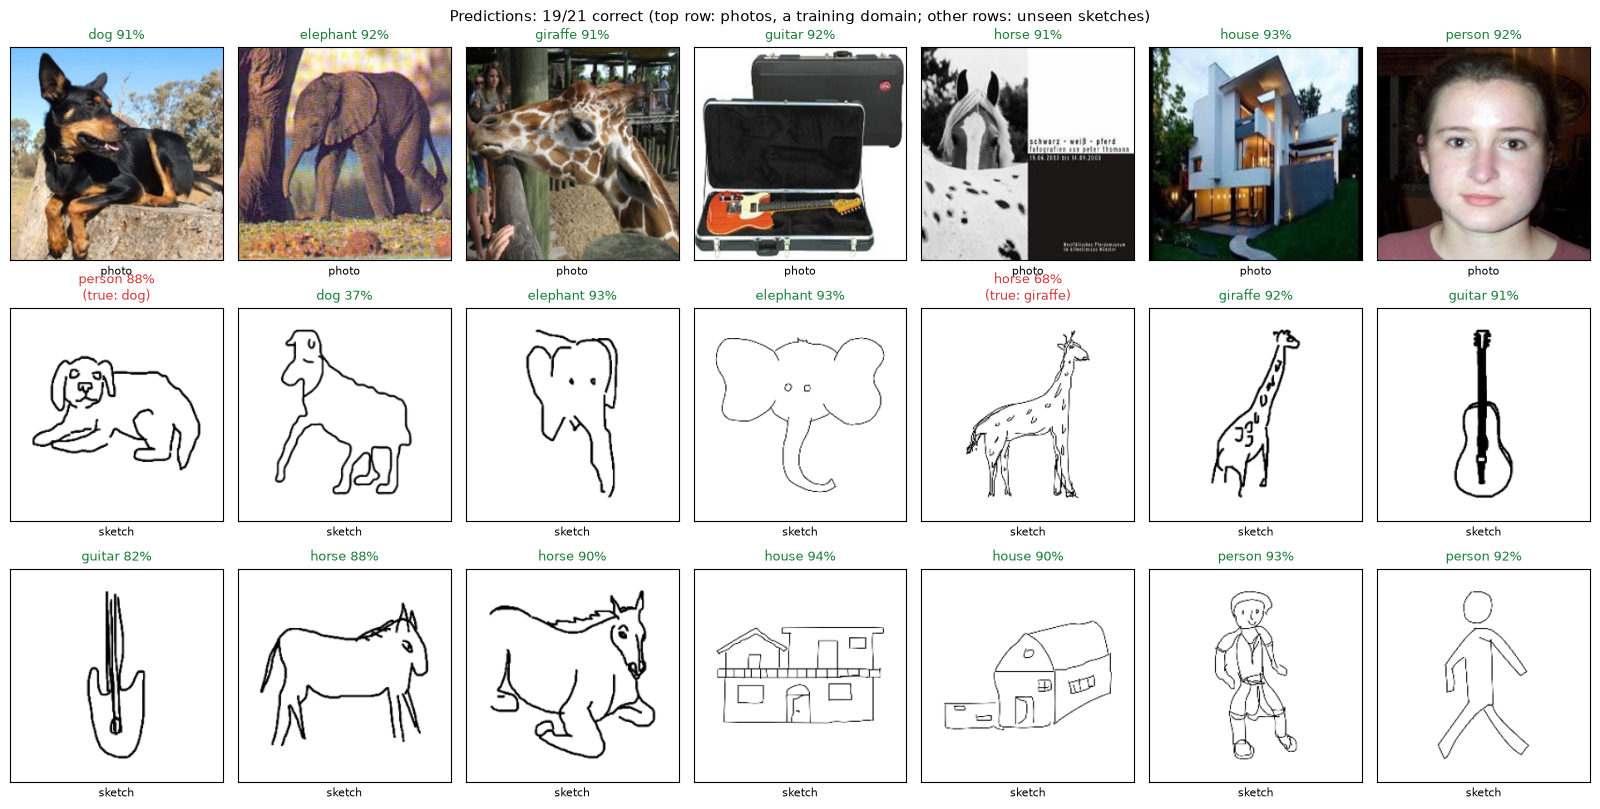

In [6]:
import torch, matplotlib.pyplot as plt
from PIL import Image as PILImage
from predict import load_model, predict, true_label

device = "cuda" if torch.cuda.is_available() else "cpu"
model, info = load_model(device=device)
print(f"Held-out domain: {info['held_out_domain']}, accuracy on all of it: {info['test_acc'] * 100:.1f}%")

paths = sorted(glob.glob("demo_images/*.png"))
results = predict(model, info, paths, device)
cols = 7
fig, axes = plt.subplots((len(paths) + cols - 1) // cols, cols, figsize=(2.3 * cols, 2.7 * ((len(paths) + cols - 1) // cols)))
right = 0
for ax, (p, pred, conf, _) in zip(axes.flat, results):
    truth = true_label(p, info["classes"])
    ok = truth == pred
    right += ok
    ax.imshow(PILImage.open(p))
    ax.set_title(f"{pred} {conf * 100:.0f}%" + ("" if ok else f"\n(true: {truth})"), fontsize=9,
                 color="#1a7f37" if ok else "#d03b3b")
    ax.set_xlabel(os.path.basename(p).split("_")[0], fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])
for ax in list(axes.flat)[len(paths):]:
    ax.axis("off")
fig.suptitle(f"Predictions: {right}/{len(paths)} correct (top row: photos, a training domain; other rows: unseen sketches)", fontsize=11)
fig.tight_layout()
plt.show()

### Try your own image
Put any image path below (a drawing, a photo, a cartoon of a dog, elephant, giraffe, guitar, horse, house or person).

In [7]:
my_images = ["demo_images/sketch_guitar_1.png"]   # replace with your own file(s)
for p, pred, conf, probs in predict(model, info, my_images, device):
    print(os.path.basename(p))
    for c, pr in sorted(zip(info["classes"], probs.tolist()), key=lambda t: -t[1])[:3]:
        print(f"   {c:9s} {pr * 100:5.1f}%")

sketch_guitar_1.png
   guitar     91.0%
   person      1.7%
   dog         1.6%
